# Análisis exploratorio de los datos del Brent

Notebook de apoyo al caso de uso III (*Aprendizaje automático*, UAX): exploración de los datos que
alimentan a las redes recurrentes. No entrena ningún modelo; usa las mismas funciones de limpieza y de
variables que el pipeline (`src/data_cleaning.py` y `src/feature_engineering.py`).

**Pipeline completo** (en `scripts/`, en orden): `01_download_data` → `02_clean_data` →
`03_train_compare_models` → `04_significance_test` → `05_error_analysis` →
`06_train_production_model` → `07_export_app_data`.

Contenido:
1. Datos en bruto: cobertura y valores faltantes
2. El Brent desde 2000 y el ciclo económico
3. Outliers: el WTI negativo y las colas de las rentabilidades
4. Volatilidad: regímenes de mercado
5. Correlaciones entre variables y con el futuro del Brent
6. Autocorrelación: por qué se predice la rentabilidad y no el precio
7. Los objetivos a 5, 63 y 252 días
8. Conclusiones para el modelado

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C
from src.data_cleaning import clean, load_raw
from src.economic_events import locate_events
from src.feature_engineering import FEATURES, build_features, build_targets

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

raw = load_raw()
df = clean(raw)
feats = build_features(df).dropna()
targets = build_targets(df["brent"]).loc[feats.index]
print(f"Datos en bruto: {raw.shape[0]} días × {raw.shape[1]} columnas ({raw.index[0]:%d/%m/%Y} → {raw.index[-1]:%d/%m/%Y})")
print(f"Tras limpiar:   {df.shape[0]} días · variables del modelo: {feats.shape[1]} · días útiles: {len(feats)}")

Datos en bruto: 7009 días × 20 columnas (04/01/2000 → 13/11/2026)
Tras limpiar:   7007 días · variables del modelo: 16 · días útiles: 6947


## 1. Datos en bruto: cobertura y valores faltantes

Fuentes: **FRED** (Brent y WTI spot de la EIA, gas Henry Hub, tipo del BCE, dólar/euro, yuan/dólar, VIX) y
**Yahoo Finance** (futuros de Brent y WTI, oro, cobre, índice del dólar). Todas las series se alinean con el
calendario del Brent en la descarga.

In [2]:
cov = pd.DataFrame({
    "primer dato": raw.apply(lambda s: s.first_valid_index()),
    "faltantes": raw.isna().sum(),
    "% faltantes": 100 * raw.isna().mean(),
}).sort_values("faltantes", ascending=False)
cov

,primer dato,faltantes,% faltantes
brent_fut_High,2007-07-30,1974,28.164
brent_fut_Low,2007-07-30,1974,28.164
brent_fut_Close,2007-07-30,1974,28.164
brent_fut_Open,2007-07-30,1974,28.164
brent_fut_Volume,2007-07-30,1974,28.164
oro,2000-08-30,171,2.440
cobre,2000-08-30,171,2.440
wti_fut_High,2000-08-23,166,2.368
wti_fut_Close,2000-08-23,166,2.368
wti_fut_Low,2000-08-23,166,2.368


Los futuros del Brent en Yahoo (`brent_fut_*`) solo existen desde 2007: por eso la **variable objetivo es el
Brent spot de la EIA** (vía FRED), con historia completa desde 2000. Los futuros no entran en el modelo; solo se
usan en la limpieza para detectar el retraso de publicación de la EIA. El resto de huecos son festivos de cada
mercado y se rellenan con el último valor disponible.

## 2. El Brent desde 2000 y el ciclo económico

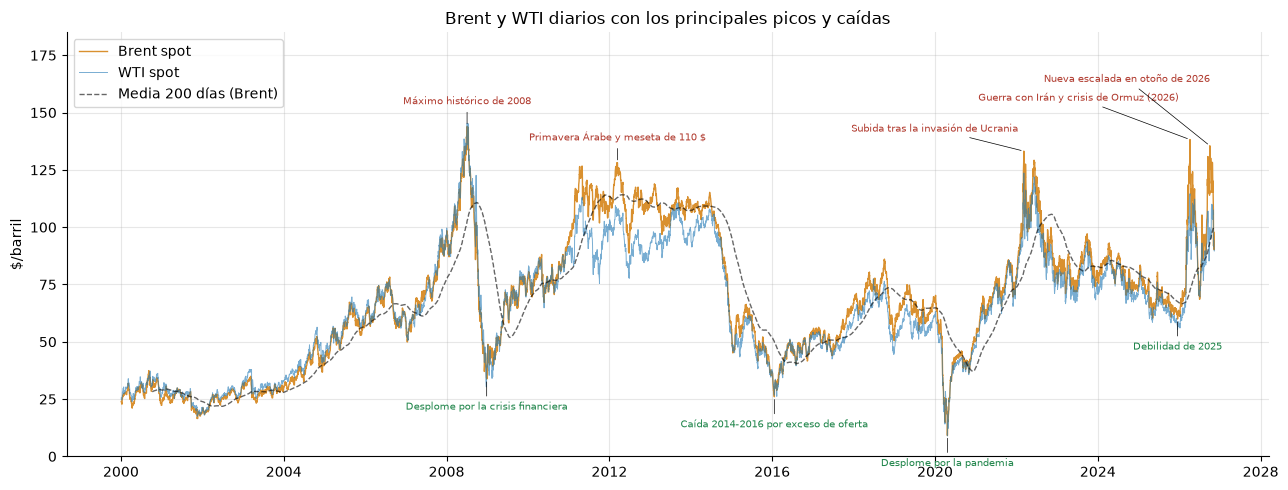

In [3]:
ev = locate_events(df["brent"])
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df.index, df["brent"], lw=1, color="#d9902f", label="Brent spot")
ax.plot(df.index, df["wti"], lw=0.7, color="#1f77b4", alpha=0.6, label="WTI spot")
ax.plot(df.index, df["brent"].rolling(200).mean(), lw=1, ls="--", color="black", alpha=0.6, label="Media 200 días (Brent)")
OFFSETS = {"2022_max": (-4, 14, "right"), "2026_max1": (-8, 28, "right"), "2026_max2": (0, 46, "right")}  # evita solapes en 2026
for _, e in ev.iterrows():
    up = e["kind"] == "max"
    dx, dy, ha = OFFSETS.get(e["id"], (0, 16 if up else -22, "center"))
    ax.annotate(e["title"], (e["date"], e["price"]), xytext=(dx, dy), textcoords="offset points",
                ha=ha, fontsize=7.5, arrowprops=dict(arrowstyle="-", lw=0.5),
                color="#b03a2e" if up else "#1e8449")
ax.set_ylim(0, 185)
ax.set_ylabel("$/barril"); ax.set_title("Brent y WTI diarios con los principales picos y caídas")
ax.legend(loc="upper left")
plt.tight_layout()

In [4]:
ev[["title", "cycle", "date", "price"]].rename(columns={"title": "evento", "cycle": "ciclo económico",
                                                        "date": "fecha", "price": "precio ($)"})

,evento,ciclo económico,fecha,precio ($)
0,Máximo histórico de 2008,Final de una expansión mundial,2008-07-03,143.95
1,Desplome por la crisis financiera,Recesión mundial,2008-12-26,33.73
2,Primavera Árabe y meseta de 110 $,Recuperación post-crisis,2012-03-13,128.14
3,Caída 2014-2016 por exceso de oferta,Desaceleración de emergentes y exceso de oferta,2016-01-20,26.01
4,Desplome por la pandemia,Recesión por la COVID-19,2020-04-21,9.12
5,Subida tras la invasión de Ucrania,Reapertura post-COVID + shock geopolítico,2022-03-08,133.18
6,Debilidad de 2025,Tensiones comerciales y más oferta OPEP+,2025-12-16,59.93
7,Guerra con Irán y crisis de Ormuz (2026),Shock de oferta geopolítico,2026-04-07,138.21
8,Nueva escalada en otoño de 2026,Riesgo geopolítico persistente,2026-10-02,135.51


El precio pasa por regímenes muy distintos: la expansión hasta 2008, el colapso de la crisis financiera, la meseta
de 2011-2014, el exceso de oferta de 2014-2016, la pandemia, Ucrania y el shock de Ormuz de 2026. **Esta no
estacionariedad es la razón de usar validación cruzada walk-forward con tres periodos distintos** (2017-18,
2019-20 y 2021-22) en vez de un único bloque de validación.

## 3. Outliers: el WTI negativo y las colas de las rentabilidades

WTI <= 0 en los datos en bruto:
            brent    wti
Date                    
2020-04-20  17.36 -36.98


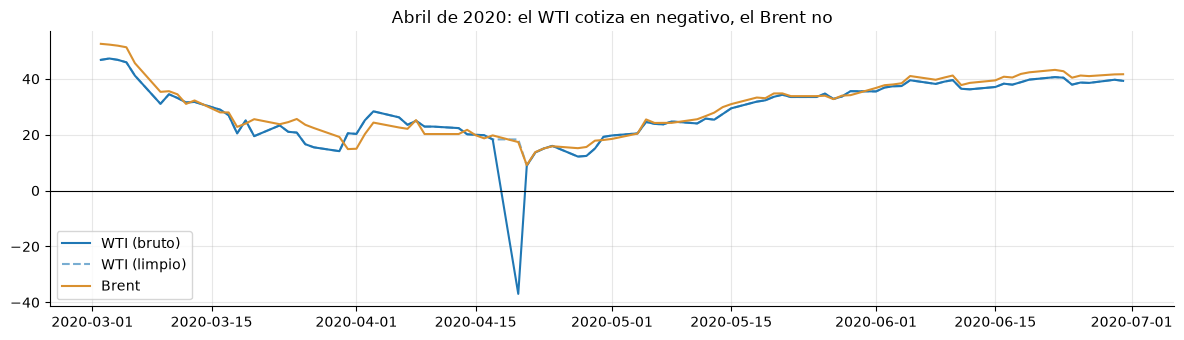

In [5]:
print("WTI <= 0 en los datos en bruto:")
print(raw.loc[raw["wti"] <= 0, ["brent", "wti"]])
fig, ax = plt.subplots(figsize=(12, 3.5))
w = raw.loc["2020-03-01":"2020-06-30"]
ax.plot(w.index, w["wti"], color="#1f77b4", label="WTI (bruto)")
ax.plot(w.index, df.loc[w.index, "wti"], color="#1f77b4", ls="--", alpha=.6, label="WTI (limpio)")
ax.plot(w.index, w["brent"], color="#d9902f", label="Brent")
ax.axhline(0, color="black", lw=.8); ax.legend(); ax.set_title("Abril de 2020: el WTI cotiza en negativo, el Brent no")
plt.tight_layout()

El WTI negativo (−36,98 $ en la serie spot de la EIA; −37,63 $ el contrato de futuros) fue una anomalía técnica
del vencimiento del contrato (no había dónde almacenar el crudo), no un precio económico. Se trata como dato faltante. El Brent, que se liquida de otra forma, no llegó a negativo:
otra razón para usarlo como variable objetivo.

Curtosis (exceso): 68.5  ·  asimetría: -1.80  ·  límites de winsorización: -0.087 / 0.080


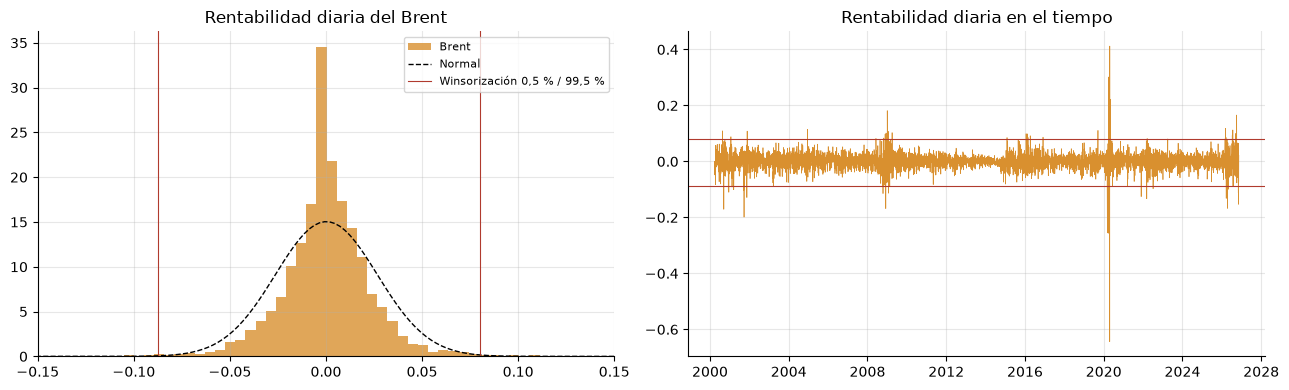

In [6]:
r = feats["ret_brent"]
lo, hi = r.quantile([0.005, 0.995])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(r, bins=200, color="#d9902f", alpha=.8, density=True, label="Brent")
x = np.linspace(r.min(), r.max(), 400)
axes[0].plot(x, np.exp(-(x - r.mean())**2 / (2 * r.var())) / np.sqrt(2 * np.pi * r.var()), "k--", lw=1, label="Normal")
axes[0].axvline(lo, color="#b03a2e", lw=.8); axes[0].axvline(hi, color="#b03a2e", lw=.8, label="Winsorización 0,5 % / 99,5 %")
axes[0].set_xlim(-0.15, 0.15); axes[0].set_title("Rentabilidad diaria del Brent"); axes[0].legend(fontsize=8)
axes[1].plot(r.index, r, lw=.5, color="#d9902f"); axes[1].axhline(lo, color="#b03a2e", lw=.8); axes[1].axhline(hi, color="#b03a2e", lw=.8)
axes[1].set_title("Rentabilidad diaria en el tiempo")
plt.tight_layout()
print(f"Curtosis (exceso): {r.kurt():.1f}  ·  asimetría: {r.skew():.2f}  ·  límites de winsorización: {lo:.3f} / {hi:.3f}")

Las rentabilidades tienen **colas mucho más gruesas que una normal** (curtosis muy alta): unos pocos días extremos
(2008, 2020, 2022, 2026) dominarían un error cuadrático. Por eso el modelo **winsoriza** las rentabilidades de
entrada al 0,5 % / 99,5 % (con límites calculados solo en entrenamiento) y se entrena con **error de Huber**, que
penaliza linealmente los errores grandes.

## 4. Volatilidad: regímenes de mercado

Volatilidad media anual (%): 2000: 48, 2001: 44, 2002: 31, 2003: 34, 2004: 35, 2005: 32, 2006: 29, 2007: 26, 2008: 43, 2009: 48, 2010: 27, 2011: 27, 2012: 22, 2013: 17, 2014: 16, 2015: 38, 2016: 44, 2017: 26, 2018: 27, 2019: 32, 2020: 75, 2021: 31, 2022: 44, 2023: 33, 2024: 26, 2025: 29, 2026: 64


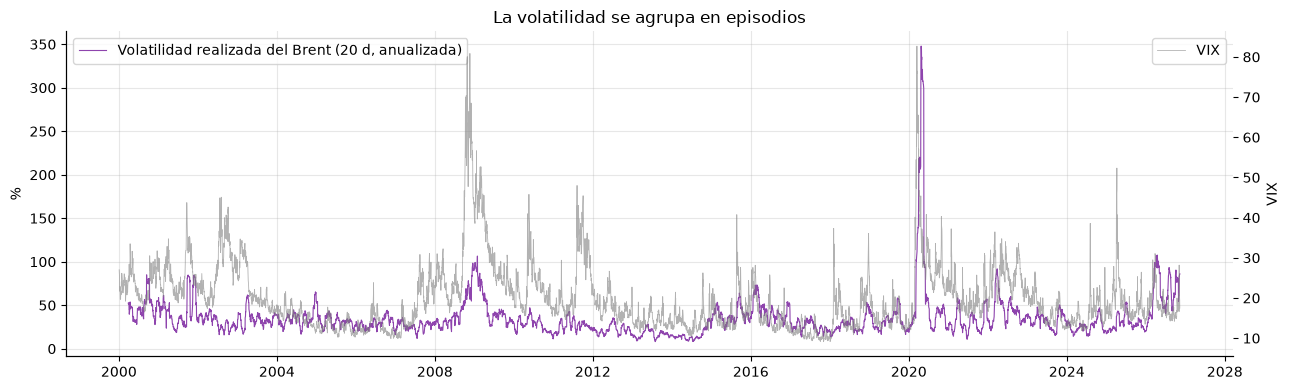

In [7]:
vol = feats["vol_brent_20"] * np.sqrt(252) * 100
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(vol.index, vol, lw=.8, color="#8e44ad", label="Volatilidad realizada del Brent (20 d, anualizada)")
ax2 = ax.twinx(); ax2.plot(df.index, df["vix"], lw=.6, color="gray", alpha=.6, label="VIX"); ax2.set_ylabel("VIX")
ax2.grid(False)
ax.set_ylabel("%"); ax.set_title("La volatilidad se agrupa en episodios"); ax.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout()
print("Volatilidad media anual (%):", ", ".join(f"{y}: {v:.0f}" for y, v in vol.groupby(vol.index.year).mean().items()))

La volatilidad aparece en rachas (*volatility clustering*) y se mueve junto al VIX en las crisis globales. Por eso
`vol_brent_20` y `log_vix` entran en el modelo, y el rango de incertidumbre del 80 % es empírico (cuantiles de los
errores reales) en vez de suponer una distribución normal. El análisis de errores (`reports/error_analysis.md`)
evalúa el modelo por separado en calma, normalidad y turbulencia.

## 5. Correlaciones entre variables y con el futuro del Brent

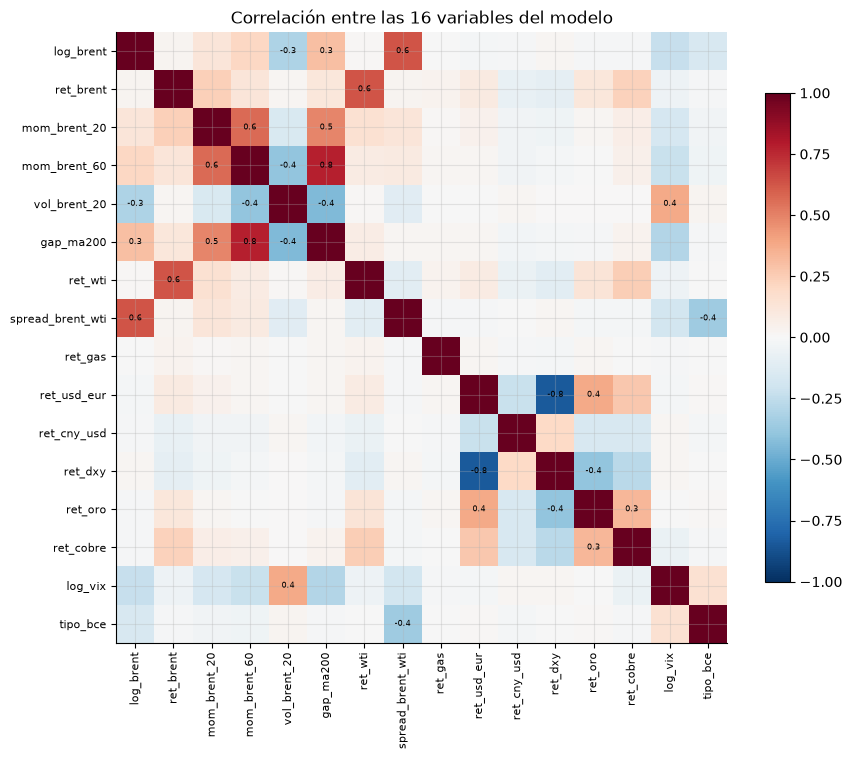

In [8]:
corr = feats.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        if abs(corr.iloc[i, j]) >= 0.3 and i != j:
            ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, shrink=.8); ax.set_title("Correlación entre las 16 variables del modelo")
plt.tight_layout()

In [9]:
fut = pd.DataFrame({name: feats.corrwith(targets[f"h{h}"]) for name, h in C.HORIZONS.items()})
fut.columns = [f"{c} ({h} d)" for c, h in zip(fut.columns, C.HORIZONS.values())]
fut.sort_values(fut.columns[1], key=abs, ascending=False).style.background_gradient(cmap="RdBu_r", vmin=-.3, vmax=.3).format("{:+.3f}")

,corto (5 d),medio (63 d),largo (252 d)
vol_brent_20,+0.073,+0.247,+0.320
log_brent,-0.069,-0.245,-0.427
gap_ma200,-0.033,-0.196,-0.220
mom_brent_60,-0.008,-0.180,-0.157
spread_brent_wti,-0.074,-0.114,-0.227
log_vix,-0.041,+0.091,+0.166
mom_brent_20,+0.049,-0.065,-0.075
tipo_bce,-0.019,-0.055,-0.084
ret_cobre,+0.033,+0.052,+0.024
ret_dxy,-0.015,-0.026,-0.026


- Entre variables: las rentabilidades del Brent y del WTI están muy correlacionadas (≈ 0,6) y el dólar/euro y el
  índice del dólar son casi el reflejo uno del otro (≈ −0,8). El resto aporta información bastante distinta.
- **Con el futuro del Brent, las correlaciones son muy pequeñas** (en valor absoluto, del orden de 0,1 o menos a
  corto plazo). Es la firma de un mercado casi eficiente: el pasado contiene poca información sobre el futuro.
  Por eso batir al modelo ingenuo («el precio futuro = el de hoy») es difícil y las mejoras esperables son de
  pocos puntos porcentuales.
- A medio y largo plazo la relación es algo más fuerte (≈ 0,2-0,4) en las variables de **nivel, tendencia y
  volatilidad**: con el precio alto o muy por encima de su media de 200 días (`log_brent`, `gap_ma200`,
  `mom_brent_60`, signo negativo) tiende a bajar después, y tras episodios de mucha volatilidad (`vol_brent_20`,
  normalmente caídas) tiende a recuperarse. Es una cierta **reversión a la media**, que es lo que el modelo
  aprovecha a medio plazo, el horizonte en el que más aporta.

## 6. Autocorrelación: por qué se predice la rentabilidad y no el precio

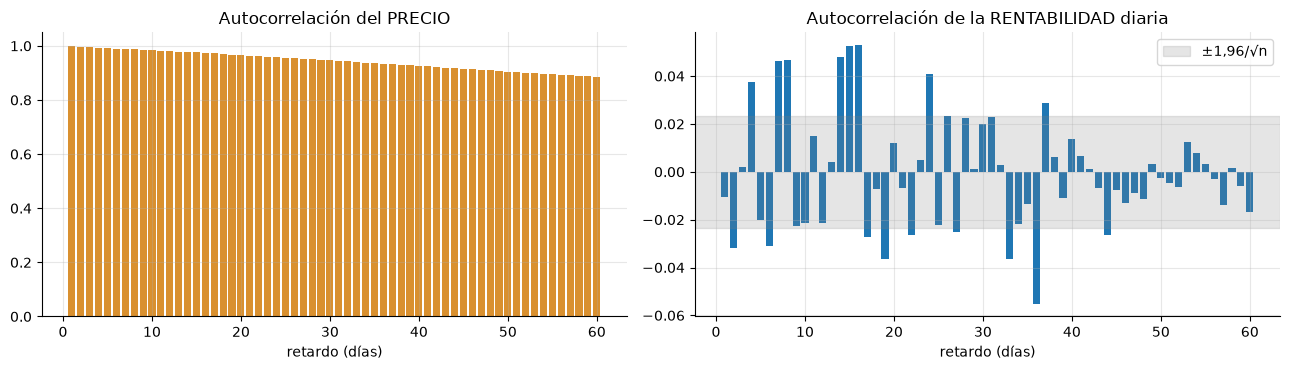

In [10]:
def acf(s, lags):
    s = s.dropna()
    return [s.autocorr(l) for l in lags]

lags = range(1, 61)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(lags, acf(df["brent"], lags), color="#d9902f"); axes[0].set_ylim(0, 1.05)
axes[0].set_title("Autocorrelación del PRECIO"); axes[0].set_xlabel("retardo (días)")
a = acf(feats["ret_brent"], lags)
band = 1.96 / np.sqrt(len(feats))
axes[1].bar(lags, a, color="#1f77b4"); axes[1].axhspan(-band, band, color="gray", alpha=.2, label="±1,96/√n")
axes[1].set_title("Autocorrelación de la RENTABILIDAD diaria"); axes[1].set_xlabel("retardo (días)"); axes[1].legend()
plt.tight_layout()

El **precio** está casi perfectamente autocorrelacionado (no estacionario): una red que lo predijera directamente
aprendería a copiar el último valor, y un R² sobre el precio sale alto incluso para el modelo ingenuo. La
**rentabilidad** apenas tiene autocorrelación. Por eso:

1. El objetivo de la red es la **rentabilidad logarítmica a h días**, `log(P[t+h] / P[t])`; predecir 0 equivale al
   modelo ingenuo, así que todo lo que la red aporte es mejora real sobre él.
2. En la evaluación se reporta, además del R² sobre el precio, el **R² fuera de muestra frente al ingenuo**.
3. Las redes con mucha capacidad sobreajustan enseguida (hay poca señal que aprender): las épocas se eligen con
   la curva de validación cruzada.

## 7. Los objetivos a 5, 63 y 252 días

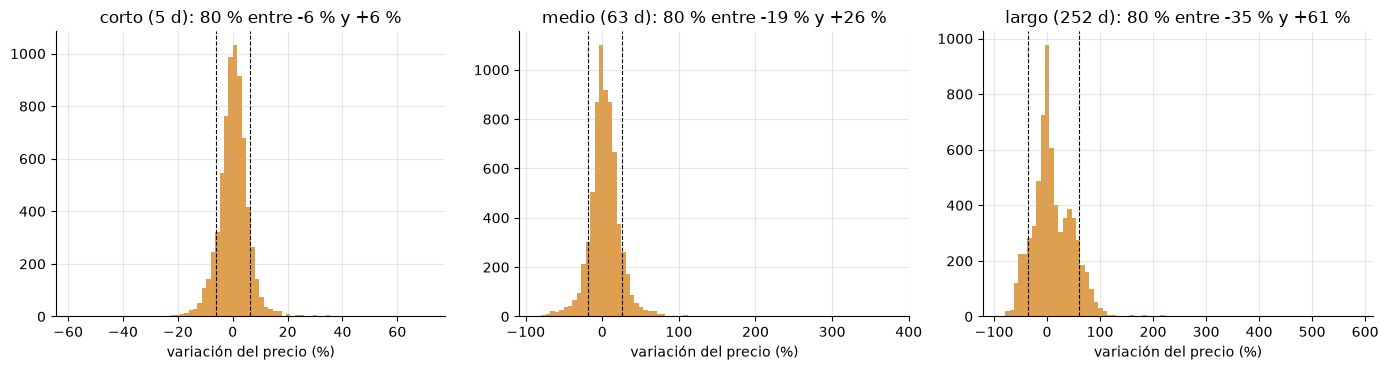

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (name, h) in zip(axes, C.HORIZONS.items()):
    t = 100 * (np.exp(targets[f"h{h}"].dropna()) - 1)
    ax.hist(t, bins=80, color="#d9902f", alpha=.85)
    q10, q90 = t.quantile([.1, .9])
    ax.axvline(q10, color="black", ls="--", lw=.8); ax.axvline(q90, color="black", ls="--", lw=.8)
    ax.set_title(f"{name} ({h} d): 80 % entre {q10:+.0f} % y {q90:+.0f} %"); ax.set_xlabel("variación del precio (%)")
plt.tight_layout()

La incertidumbre crece mucho con el horizonte: a una semana el precio suele moverse unos pocos puntos; a un año,
el 80 % central de los casos abarca desde caídas fuertes hasta subidas muy grandes. Además, a 252 días solo hay
unas pocas decenas de periodos anuales independientes en toda la muestra: **es el horizonte con menos información
efectiva**, y el que el análisis de significación (Diebold-Mariano) confirma que no es fiable.

## 8. Conclusiones para el modelado

| Observación | Decisión en el modelo |
|---|---|
| El Brent spot de la EIA tiene historia completa desde 2000; los futuros de Yahoo, solo desde 2007 | Variable objetivo: Brent spot (FRED) |
| Festivos distintos en cada mercado | Calendario del Brent y relleno con el último valor |
| WTI negativo en 2020 (anomalía técnica) | Tratado como dato faltante |
| Colas gruesas en las rentabilidades | Winsorización (ajustada solo en entrenamiento) y error de Huber |
| Regímenes de mercado muy distintos | Validación cruzada walk-forward con tres periodos y test 2023 → hoy |
| Volatilidad en rachas | Volatilidad y VIX como variables; intervalo del 80 % empírico |
| Precio no estacionario, rentabilidad casi sin memoria | Se predice la rentabilidad logarítmica; referencia: modelo ingenuo |
| Correlaciones con el futuro muy débiles | Mejoras esperables pequeñas; se comprueba su significación (Diebold-Mariano) |
| Pocos años independientes a 252 días | El largo plazo se presenta con su rango y fiabilidad baja |

Siguiente paso: `scripts/03_train_compare_models.py` (comparativa RNN / LSTM / GRU) y sus resultados en
`reports/comparison.md`.